# Demo 2 sensitivity: spatially correlated parameter shocks

A sensitivity analysis, outside the three-model comparison and not yet in the manuscript:
the two county models again, with their counties' daily parameter shocks correlated in
space. The ensembles come from the commands below, not from `scripts/run-demos.sh`.

## Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from manuscript_analysis.demos import paths
from manuscript_analysis.demos.covid import evaluation as ev_mod
from manuscript_analysis.demos.covid.models import covid_season
from manuscript_analysis.demos.covid.seasons import seasons
from manuscript_analysis.demos.lib.cli import run_season_cli
from manuscript_analysis.demos.lib.figures import save_figure, use_manuscript_style

NOTEBOOK_FIGURES = paths.RESULTS / "demos" / "notebook"
REALIZATIONS = 600

use_manuscript_style()
pd.set_option("display.width", 200)

## The question

The evaluation notebook's calibration panel has a candidate mechanism. At their own counties the county models are
well calibrated, but summed to states their median drifts up with horizon and their 95%
coverage falls. County forecasts are right-skewed, and within one realization they are
nearly **independent**: epymorph's `OrnsteinUhlenbeck` draws a separate shock for every
node every day, both while filtering and over the forecast horizon. Summing many
independent skewed forecasts pulls the median towards the mean and narrows the relative
spread, so the state sum is too confident.

The test swaps that process for `CorrelatedOU` (`models/correlated_ou.py`, adapted from
`FluSight-pipeline/flu/correlated.py`), which draws each day's 32 county shocks jointly.
Their correlation is

$$\rho_{ij} = c\, e^{-d_{ij}/L} + (1 - c)\,\mathbb{1}[i = j],$$

with $d_{ij}$ the distance between county internal points in miles and $c$ the share of
each shock that is spatially structured. The diagonal is always 1, so **each county's own
process is unchanged**; only how the counties move together differs. It is used while
filtering and while forecasting, for both `log_beta` and `log_death_prob`.

| setting | $L$ | $c$, `log_beta` | $c$, `log_death_prob` | what it is |
|---|---|---|---|---|
| `CORRELATION_FITTED` | 200 mi | 0.3 | 0.1 | fitted to the data |
| `CORRELATION_STRONG` | 200 mi | 1 | 1 | a pure kernel: an upper bracket |

**How the fitted values were chosen, without forecast scores.** Two independent sources:
the week-to-week changes in the independent county models' filtered `log_beta` medians,
and the weekly log growth of the observed census. Both give $L \approx 200$ miles and
$c \approx 0.3$, and same-state pairs are no more correlated than cross-state pairs at the
same distance. `log_death_prob` changes correlate at only about 0.1 with no clear decay
in distance, so it keeps $L$ with a small $c$. A pure kernel ($c = 1$) can only match the
data at $L \approx 20$-$40$ miles, and has the wrong shape there.

**What it cannot do.** Even $c = 1$ does not turn the county models into the state model:
the EnKF still updates each county from its own data alone. This measures how much of
the gap correlated noise explains, not whether it explains all of it.

In [2]:
from manuscript_analysis.demos.covid.models import spatial_movement

for setting in (covid_season.CORRELATION_FITTED, covid_season.CORRELATION_STRONG):
    print(setting)

# The correlated models are the county models with one argument added. The only
# epymorph-facing change is the parameter dynamics: `CorrelatedOU` is a
# `ParamFunctionDynamics`, like the built-in `OrnsteinUhlenbeck` it replaces.
print()
for model in (spatial_movement.county, spatial_movement.county_correlated):
    dynamics = {
        name: type(param.dynamics).__name__
        for name, param in model.unknown_params.items()
    }
    print(f"{model.name:18s} {dynamics}")

SpatialCorrelation(length_scale=200.0, beta_shared=0.3, death_prob_shared=0.1)
SpatialCorrelation(length_scale=200.0, beta_shared=1.0, death_prob_shared=1.0)

county             {'ipm::log_beta': 'OrnsteinUhlenbeck', 'ipm::log_death_prob': 'OrnsteinUhlenbeck'}
county-correlated  {'ipm::log_beta': 'CorrelatedOU', 'ipm::log_death_prob': 'CorrelatedOU'}


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


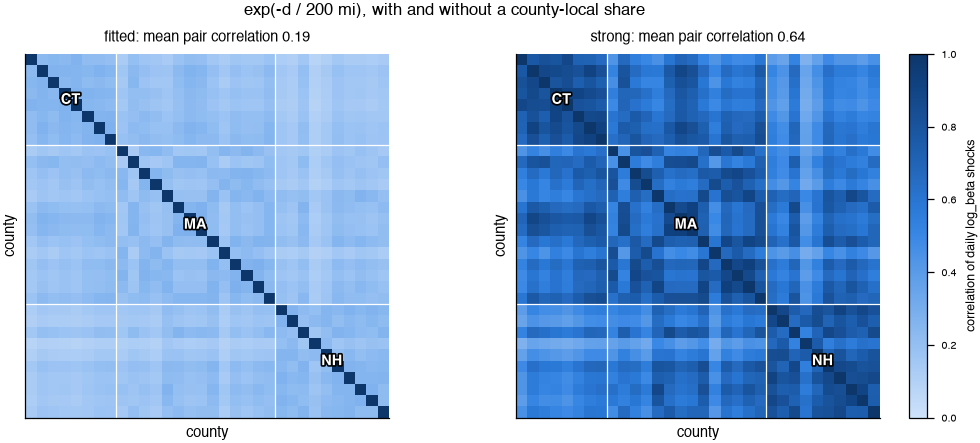

In [3]:
# The correlation of the daily log_beta shocks under each setting, drawn like
# Figure 3(a): commuting couples the counties in `movement`; this couples their
# parameters. Pass "log_death_prob" for the other parameter.
fig = ev_mod.figure_parameter_correlation("log_beta")
save_figure(fig, "covid-parameter-correlation", figure_dir=NOTEBOOK_FIGURES)
plt.show()

### Running them

Four models at both seeds, written to `results/demos/notebook/correlated-ou/` rather than
`runs/`: they are exploratory, so they stay gitignored and outside `MANIFEST.sha256`.
Same cost as their twins, about 35 minutes for a county model and 86 for a movement model
at 600 realizations. From a terminal, in parallel:

```sh
cd analysis
for seed in 0 1; do
  for m in movement_correlated movement_correlated_strong \
           county_correlated county_correlated_strong; do
    python -m manuscript_analysis.demos.covid.run_season models.spatial_movement:$m \
      -n 600 --seed $seed -o ../results/demos/notebook/correlated-ou/covid/seed$seed/${m//_/-} &
  done
done
wait
```

In [4]:
CORRELATED_SPECS = [
    "models.spatial_movement:county_correlated",
    "models.spatial_movement:county_correlated_strong",
    "models.spatial_movement:movement_correlated",
    "models.spatial_movement:movement_correlated_strong",
]

# Off by default, unlike section 1: these take hours, and a run that is still going has
# no run.json yet, so this cell would start a second copy into the same folder. When on,
# a folder produced under the same configuration is skipped, and the runs go one after
# another. Use the shell block above for a real run.
RUN_CORRELATED = False

for seed in ((0, 1) if RUN_CORRELATED else ()):
    for spec in CORRELATED_SPECS:
        run_season_cli(
            seasons,
            default_season="COVID2020",
            output_root=lambda seed: paths.correlated_runs("covid", seed=seed),
            package="manuscript_analysis.demos.covid",
            argv=[spec, "-n", str(REALIZATIONS), "--seed", str(seed)],
        )

In [5]:
# Every model in one Evaluation per seed, so each is scored against the same target and
# each correlated model can be compared with its uncorrelated twin. Runs that have not
# finished are left out.
ev_corr = ev_mod.load_correlated(seed=0)
rep_corr = ev_mod.load_correlated(seed=1)

for label, loaded in (("seed 0", ev_corr), ("seed 1", rep_corr)):
    found = [m for m in loaded.forecasts if m in ev_mod.CORRELATED_MODELS]
    print(f"{label}: {len(found)} of {len(ev_mod.CORRELATED_MODELS)} correlated runs", found)

seed 0: 4 of 4 correlated runs ['county-correlated', 'county-correlated-strong', 'movement-correlated', 'movement-correlated-strong']
seed 1: 4 of 4 correlated runs ['county-correlated', 'county-correlated-strong', 'movement-correlated', 'movement-correlated-strong']


### What to look for

If independent county shocks are what makes the state sums overconfident, then at the
**state** scale the correlated models should have higher coverage at the longest horizon
and a `median / observed` ratio closer to 1, with the strong setting moving further than
the fitted one. `rel uncorrelated` is the direct contrast: the same model with
independent shocks. Below 1 means correlation helped.

At the **county** scale, `county-correlated` should be statistically unchanged from
`county` (`rel uncorrelated` near 1), because each county's own process is the same. The
movement models need not be, since commuting couples the counties' epidemics.

In [6]:
# The scored (state) scale, both seeds.
for label, loaded in (("seed 0", ev_corr), ("seed 1", rep_corr)):
    print(f"--- {label}, scale: {loaded.scale}")
    display(ev_mod.correlated_table(loaded).round(3))

--- seed 0, scale: log


log WIS  rel log WIS  rel uncorrelated  cov50  cov95  cov95 h3  median / observed h3
quantity model                                                                                                           
census   movement                      0.159        1.079               NaN  0.295  0.753     0.639                 1.292
         county                        0.167        1.123               NaN  0.288  0.774     0.639                 1.351
         state                         0.136        1.000               NaN  0.510  1.000     1.000                 1.178
         county-correlated             0.155        1.099             0.979  0.337  0.910     0.833                 1.303
         county-correlated-strong      0.152        1.127             1.004  0.455  0.979     0.986                 1.265
         movement-correlated           0.153        1.095             1.014  0.323  0.878     0.778                 1.258
         movement-correlated-strong    0.140        1.059             0.981  0.438  0.993     1.000                 1.154
deaths   movement                      0.160        0.997               NaN  0.385  0.872     0.778                 1.323
         county                        0.165        1.018               NaN  0.382  0.844     0.750                 1.371
         state                         0.152        1.000               NaN  0.552  0.958     0.958                 1.179
         county-correlated             0.164        1.044             1.025  0.417  0.906     0.875                 1.335
         county-correlated-strong      0.161        1.081             1.061  0.514  0.972     0.986                 1.291
         movement-correlated           0.156        1.012             1.015  0.434  0.910     0.903                 1.288
         movement-correlated-strong    0.148        1.023             1.027  0.580  0.979     0.986                 1.179

--- seed 1, scale: log


log WIS  rel log WIS  rel uncorrelated  cov50  cov95  cov95 h3  median / observed h3
quantity model                                                                                                           
census   movement                      0.161        1.115               NaN  0.302  0.771     0.653                 1.306
         county                        0.168        1.146               NaN  0.299  0.781     0.694                 1.355
         state                         0.133        1.000               NaN  0.545  0.997     1.000                 1.161
         county-correlated             0.154        1.120             0.977  0.337  0.868     0.778                 1.327
         county-correlated-strong      0.149        1.143             0.997  0.472  0.993     1.000                 1.247
         movement-correlated           0.148        1.102             0.988  0.344  0.872     0.806                 1.259
         movement-correlated-strong    0.146        1.124             1.008  0.448  0.997     1.000                 1.184
deaths   movement                      0.159        1.019               NaN  0.392  0.861     0.750                 1.340
         county                        0.171        1.064               NaN  0.365  0.837     0.722                 1.378
         state                         0.148        1.000               NaN  0.562  0.958     0.944                 1.170
         county-correlated             0.159        1.047             0.984  0.434  0.906     0.861                 1.352
         county-correlated-strong      0.155        1.075             1.010  0.556  0.979     0.986                 1.273
         movement-correlated           0.151        1.011             0.992  0.441  0.931     0.931                 1.298
         movement-correlated-strong    0.152        1.057             1.037  0.556  0.979     0.972                 1.209

In [7]:
# The sanity check on the design: the same models at their own 32 counties.
for label, loaded in (("seed 0", ev_corr), ("seed 1", rep_corr)):
    print(f"--- {label}")
    display(ev_mod.correlated_county_table(loaded).round(3))

--- seed 0


log WIS  rel uncorrelated  cov95
quantity model                                                       
census   movement                      0.228               NaN  0.956
         county                        0.249               NaN  0.972
         county-correlated             0.243             0.984  0.971
         county-correlated-strong      0.248             1.001  0.971
         movement-correlated           0.230             1.013  0.958
         movement-correlated-strong    0.222             0.995  0.969
deaths   movement                      0.233               NaN  0.948
         county                        0.249               NaN  0.940
         county-correlated             0.256             1.016  0.936
         county-correlated-strong      0.252             1.022  0.940
         movement-correlated           0.234             1.011  0.952
         movement-correlated-strong    0.234             1.011  0.952

--- seed 1


log WIS  rel uncorrelated  cov95
quantity model                                                       
census   movement                      0.231               NaN  0.952
         county                        0.247               NaN  0.972
         county-correlated             0.246             0.997  0.967
         county-correlated-strong      0.253             1.023  0.971
         movement-correlated           0.227             0.992  0.958
         movement-correlated-strong    0.229             1.008  0.963
deaths   movement                      0.235               NaN  0.950
         county                        0.252               NaN  0.935
         county-correlated             0.251             0.988  0.937
         county-correlated-strong      0.252             0.999  0.939
         movement-correlated           0.234             0.998  0.951
         movement-correlated-strong    0.236             0.994  0.951